# Level 2 - Task 2: Cuisine Combination

**Objective:**
1. Identify the most common combinations of cuisines in the dataset.
2. Determine if certain cuisine combinations tend to have higher ratings.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
%matplotlib inline

# Load dataset
df = pd.read_csv(r'C:\Users\acer\OneDrive\Desktop\Cognifyz-Internship\Dataset.csv')

# Drop rows with no cuisine data
df_clean = df.dropna(subset=['Cuisines'])

print(f"✅ Dataset loaded!")
print(f"Total Restaurants: {len(df)}")
print(f"Restaurants with Cuisine data: {len(df_clean)}")
print(f"\nSample Cuisines:")
print(df_clean['Cuisines'].head(10).to_string())

✅ Dataset loaded!
Total Restaurants: 9551
Restaurants with Cuisine data: 9542

Sample Cuisines:
0            French, Japanese, Desserts
1                              Japanese
2      Seafood, Asian, Filipino, Indian
3                       Japanese, Sushi
4                      Japanese, Korean
5                               Chinese
6                       Asian, European
7    Seafood, Filipino, Asian, European
8               European, Asian, Indian
9                              Filipino


In [2]:
# Count exact cuisine combinations
combo_counts = df_clean['Cuisines'].value_counts()

print("=" * 70)
print("🍽️ TOP 15 MOST COMMON CUISINE COMBINATIONS")
print("=" * 70)

for rank, (combo, count) in enumerate(combo_counts.head(15).items(), 1):
    pct = (count / len(df_clean)) * 100
    print(f"{rank:2d}. {combo:55s} → {count:4d} ({pct:.2f}%)")

🍽️ TOP 15 MOST COMMON CUISINE COMBINATIONS
 1. North Indian                                            →  936 (9.81%)
 2. North Indian, Chinese                                   →  511 (5.36%)
 3. Chinese                                                 →  354 (3.71%)
 4. Fast Food                                               →  354 (3.71%)
 5. North Indian, Mughlai                                   →  334 (3.50%)
 6. Cafe                                                    →  299 (3.13%)
 7. Bakery                                                  →  218 (2.28%)
 8. North Indian, Mughlai, Chinese                          →  197 (2.06%)
 9. Bakery, Desserts                                        →  170 (1.78%)
10. Street Food                                             →  149 (1.56%)
11. Pizza, Fast Food                                        →  131 (1.37%)
12. Chinese, Fast Food                                      →  118 (1.24%)
13. Mithai, Street Food                                  

In [3]:
# Kitne restaurants single cuisine serve karte hain vs multiple
df_clean['Cuisine_Count'] = df_clean['Cuisines'].apply(lambda x: len(x.split(', ')))

cuisine_count_dist = df_clean['Cuisine_Count'].value_counts().sort_index()

print("=" * 60)
print("📊 CUISINE COUNT DISTRIBUTION")
print("=" * 60)
print(f"{'No. of Cuisines':<20} {'Restaurants':<15} {'Percentage':<15}")
print("-" * 60)

for count, restaurants in cuisine_count_dist.items():
    pct = (restaurants / len(df_clean)) * 100
    label = "Single Cuisine" if count == 1 else f"{count} Cuisines"
    print(f"{label:<20} {restaurants:<15} {pct:>6.2f}%")
print("=" * 60)

# Average rating by cuisine count
print("\n⭐ Average Rating by Cuisine Count:")
print("-" * 60)
avg_rating_by_count = df_clean.groupby('Cuisine_Count')['Aggregate rating'].mean()
for count, rating in avg_rating_by_count.items():
    print(f"{count} Cuisine(s) → Average Rating: {rating:.4f}")

📊 CUISINE COUNT DISTRIBUTION
No. of Cuisines      Restaurants     Percentage     
------------------------------------------------------------
Single Cuisine       3394             35.57%
2 Cuisines           3444             36.09%
3 Cuisines           1840             19.28%
4 Cuisines           584               6.12%
5 Cuisines           164               1.72%
6 Cuisines           74                0.78%
7 Cuisines           28                0.29%
8 Cuisines           14                0.15%

⭐ Average Rating by Cuisine Count:
------------------------------------------------------------
1 Cuisine(s) → Average Rating: 2.2307
2 Cuisine(s) → Average Rating: 2.6933
3 Cuisine(s) → Average Rating: 3.0392
4 Cuisine(s) → Average Rating: 3.4156
5 Cuisine(s) → Average Rating: 3.5104
6 Cuisine(s) → Average Rating: 3.6730
7 Cuisine(s) → Average Rating: 3.6714
8 Cuisine(s) → Average Rating: 3.4214


C:\Users\acer\AppData\Local\Temp\ipykernel_23472\573065554.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['Cuisine_Count'] = df_clean['Cuisines'].apply(lambda x: len(x.split(', ')))


In [4]:
# Filter combinations with minimum 10 restaurants for reliable analysis
combo_stats = df_clean.groupby('Cuisines').agg(
    count=('Restaurant ID', 'count'),
    avg_rating=('Aggregate rating', 'mean'),
    total_votes=('Votes', 'sum')
).reset_index()

# Filter combos with 10+ restaurants
popular_combos = combo_stats[combo_stats['count'] >= 10].copy()

# Top rated combinations
top_rated = popular_combos.sort_values('avg_rating', ascending=False)

print("=" * 70)
print("🏆 TOP 10 HIGHEST RATED CUISINE COMBINATIONS (Min 10 Restaurants)")
print("=" * 70)

for rank, (_, row) in enumerate(top_rated.head(10).iterrows(), 1):
    print(f"{rank:2d}. {row['Cuisines']:55s}")
    print(f"    → Rating: {row['avg_rating']:.2f} | Restaurants: {row['count']} | Votes: {row['total_votes']}")

🏆 TOP 10 HIGHEST RATED CUISINE COMBINATIONS (Min 10 Restaurants)
 1. Modern Indian                                          
    → Rating: 4.35 | Restaurants: 11 | Votes: 12355
 2. Indian                                                 
    → Rating: 4.25 | Restaurants: 18 | Votes: 6068
 3. Seafood                                                
    → Rating: 4.11 | Restaurants: 14 | Votes: 5332
 4. Thai                                                   
    → Rating: 4.10 | Restaurants: 16 | Votes: 3299
 5. Cafe, Continental, Italian                             
    → Rating: 4.08 | Restaurants: 10 | Votes: 1830
 6. American, Burger                                       
    → Rating: 4.08 | Restaurants: 13 | Votes: 6371
 7. Japanese, Sushi                                        
    → Rating: 4.04 | Restaurants: 18 | Votes: 5119
 8. Pizza, Italian                                         
    → Rating: 3.67 | Restaurants: 19 | Votes: 6046
 9. American                                  

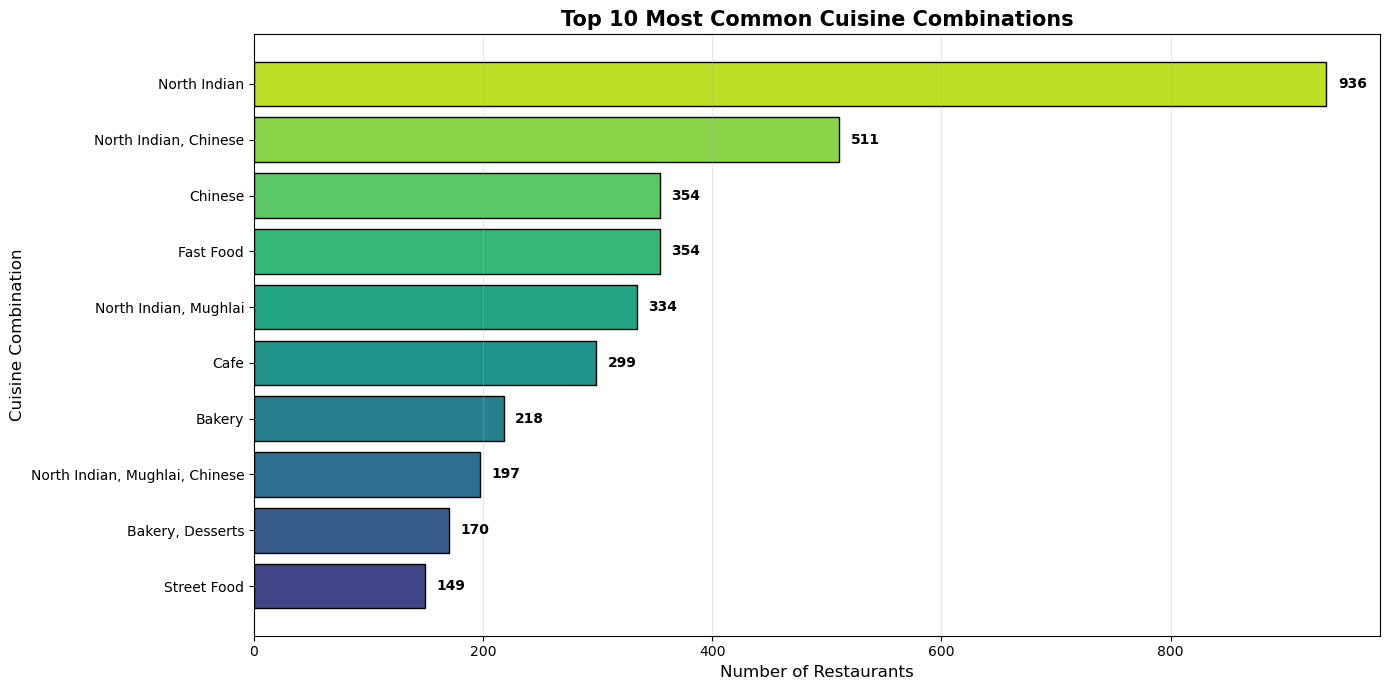

In [5]:
# Top 10 combinations by count
top_10_combos = combo_counts.head(10)

plt.figure(figsize=(14, 7))
colors = plt.cm.viridis(np.linspace(0.2, 0.9, 10))

bars = plt.barh(top_10_combos.index[::-1], top_10_combos.values[::-1],
                color=colors, edgecolor='black')

# Labels
for bar, count in zip(bars, top_10_combos.values[::-1]):
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height()/2,
             f'{count}', va='center', fontsize=10, fontweight='bold')

plt.title('Top 10 Most Common Cuisine Combinations', fontsize=15, fontweight='bold')
plt.xlabel('Number of Restaurants', fontsize=12)
plt.ylabel('Cuisine Combination', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

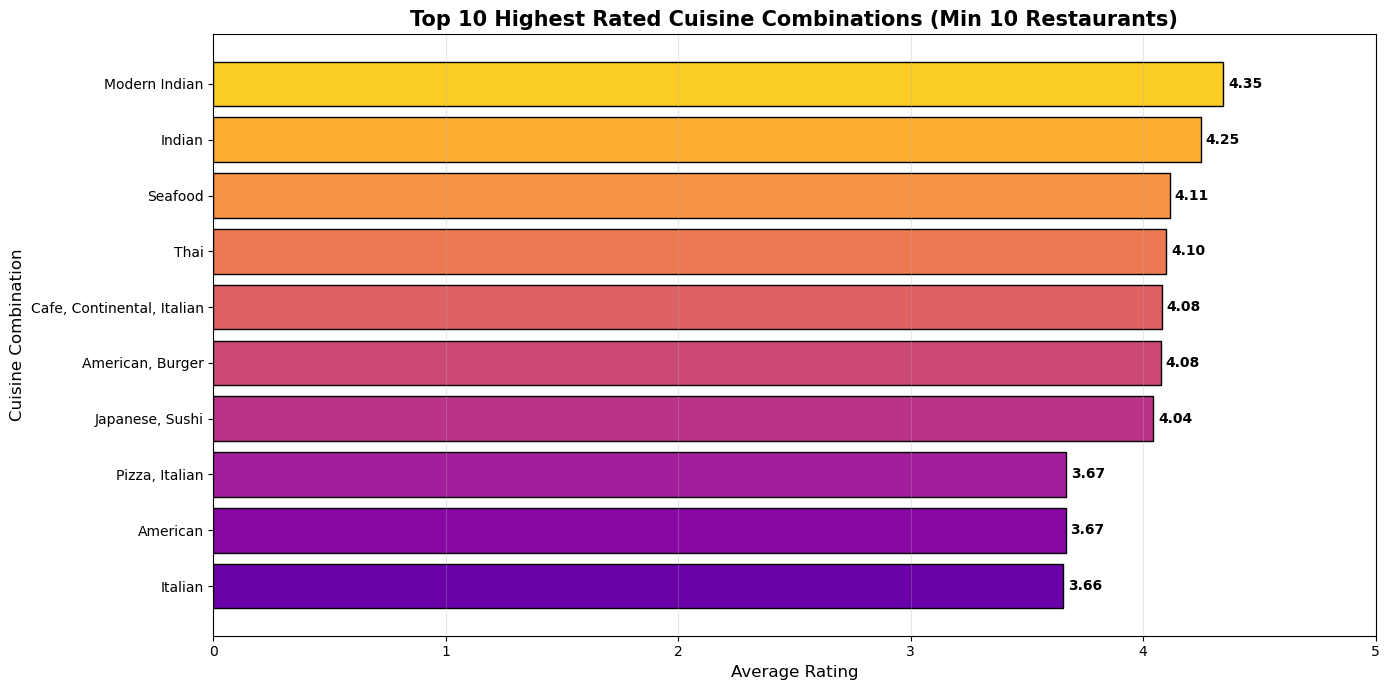

In [6]:
# Top 10 highest rated combinations
top_rated_10 = top_rated.head(10)

plt.figure(figsize=(14, 7))
colors = plt.cm.plasma(np.linspace(0.2, 0.9, 10))

bars = plt.barh(top_rated_10['Cuisines'][::-1], top_rated_10['avg_rating'][::-1],
                color=colors, edgecolor='black')

# Labels
for bar, rating in zip(bars, top_rated_10['avg_rating'][::-1]):
    width = bar.get_width()
    plt.text(width + 0.02, bar.get_y() + bar.get_height()/2,
             f'{width:.2f}', va='center', fontsize=10, fontweight='bold')

plt.title('Top 10 Highest Rated Cuisine Combinations (Min 10 Restaurants)', 
          fontsize=15, fontweight='bold')
plt.xlabel('Average Rating', fontsize=12)
plt.ylabel('Cuisine Combination', fontsize=12)
plt.xlim(0, 5)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 🔍 Insights

### 1. Most Common Cuisine Combinations
- Top combination: **{combo name}** with **{X}** restaurants
- Second: **{combo name}** with **{Y}** restaurants
- Third: **{combo name}** with **{Z}** restaurants
- Most restaurants serve **{single/multiple}** cuisines

### 2. Rating Patterns
- Average rating of restaurants with **single cuisine**: **{rating}**
- Average rating of restaurants with **multiple cuisines**: **{rating}**
- Restaurants offering **{X}** cuisines have highest average rating: **{rating}**

### 3. High-Rated Combinations
- Top-rated combination: **{name}** with rating **{rating}**
- These combinations tend to be **specialized cuisines**

### Conclusion
- Restaurants serving **multiple cuisines** attract more diverse customers
- Certain combinations consistently outperform others
- **{Single/Multiple}** cuisine restaurants tend to have higher ratings